In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load the cleaned dataset
df = pd.read_csv("Titanic-Cleaned.csv")

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (891, 10)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,0,1
1,1,1,1,38.0,1,0,71.2833,1,0,0
2,1,3,1,26.0,0,0,7.9250,0,0,1
3,1,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,0,35.0,0,0,8.0500,0,0,1


In [2]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Column Names:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked_C  891 non-null    int64  
 8   Embarked_Q  891 non-null    int64  
 9   Embarked_S  891 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 69.7 KB


In [3]:
# Feature Engineering

# Calculate total family size
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Check whether passenger was travelling alone
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

# Display new features
df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head(10)

,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1
5,0,0,1,1
6,0,0,1,1
7,3,1,5,0
8,0,2,3,0
9,1,0,2,0


In [4]:
print("Updated Dataset Shape:", df.shape)

print("\nFamily Size Distribution:")
print(df["FamilySize"].value_counts().sort_index())

print("\nPassengers Travelling Alone:")
print(df["IsAlone"].value_counts())

Updated Dataset Shape: (891, 12)

Family Size Distribution:
FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

Passengers Travelling Alone:
IsAlone
1    537
0    354
Name: count, dtype: int64


In [5]:
# Separate features and target

X = df.drop("Survived", axis=1)
y = df["Survived"]

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (712, 11)
Testing data shape: (179, 11)


In [6]:
from sklearn.model_selection import GridSearchCV

# Define parameters to test
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Create Random Forest model
rf = RandomForestClassifier(random_state=42)

# Perform Grid Search with 5-fold cross-validation
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

# Train and find the best parameters
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1 Score:", grid_search.best_score_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best Cross-Validation F1 Score: 0.7550965086511879


In [7]:
# Get the best model from Grid Search
best_model = grid_search.best_estimator_

# Make predictions on test data
y_pred = best_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Improved Random Forest Model Results")
print("-------------------------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

Improved Random Forest Model Results
-------------------------------------
Accuracy: 81.01 %
Precision: 80.7 %
Recall: 66.67 %
F1 Score: 73.02 %


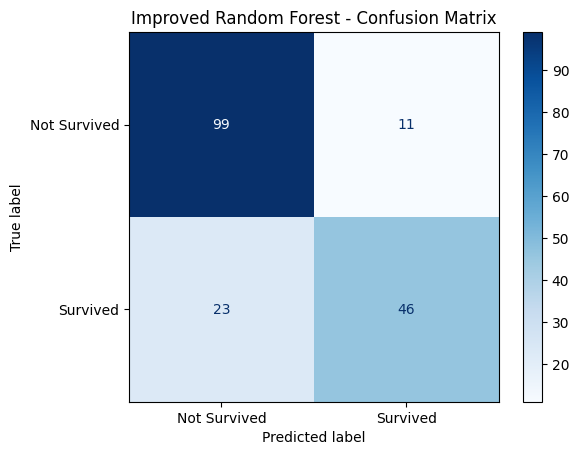

In [10]:
# Save the confusion matrix image
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

disp.plot(cmap="Blues")
plt.title("Improved Random Forest - Confusion Matrix")

plt.savefig("improved_random_forest_confusion_matrix.png", dpi=300, bbox_inches="tight")

plt.show()

In [9]:
# Compare Task 2 and Task 3 results

comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Task 2 Random Forest": [82.12, 81.36, 69.57, 75.00],
    "Task 3 Improved Random Forest": [
        round(accuracy * 100, 2),
        round(precision * 100, 2),
        round(recall * 100, 2),
        round(f1 * 100, 2)
    ]
})

comparison.to_csv("model_improvement_comparison.csv", index=False)

comparison

,Metric,Task 2 Random Forest,Task 3 Improved Random Forest
0,Accuracy,82.12,81.01
1,Precision,81.36,80.70
2,Recall,69.57,66.67
3,F1 Score,75.00,73.02
